<a href="https://colab.research.google.com/github/divyamsh8/DAV_LAB/blob/main/DAV_LAB_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.stats import zscore
data = {
    "Students": ["A","B","C","D","E","F","G","H","I","J","K","L","M","N","O"],
    "Study_Hours": [2,3,4,5,4,6,5,3,4,5,6,4,5,30,3]

}
df = pd.DataFrame(data)
print("Original Data Set")
display(df)

Original Data Set


,Students,Study_Hours
0,A,2
1,B,3
2,C,4
3,D,5
4,E,4
5,F,6
6,G,5
7,H,3
8,I,4
9,J,5


In [ ]:
df["Study_Hours"].describe()

,Study_Hours
count,15.000000
mean,5.933333
std,6.755597
min,2.000000
25%,3.500000
50%,4.000000
75%,5.000000
max,30.000000


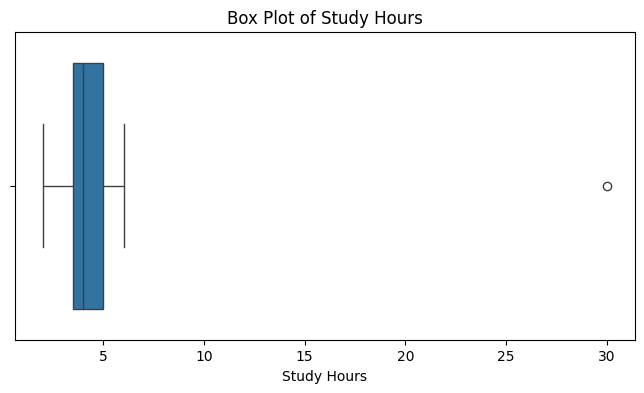

In [ ]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df["Study_Hours"])
plt.title("Box Plot of Study Hours")
plt.xlabel("Study Hours")
plt.show()

In [ ]:
Q1 = df['Study_Hours'].quantile(0.25)
Q3 = df['Study_Hours'].quantile(0.75)
print("Q1:", Q1)
print("Q3:", Q3)

Q1: 3.5
Q3: 5.0


In [ ]:
IQR =Q3-Q1
print("IQR:", IQR)

IQR: 1.5


In [ ]:
lower_bound = Q1 - 1.5 * IQR #any value above and below the bound is considered as outlier
upper_bound = Q3 + 1.5 * IQR
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: 1.25
Upper Bound: 7.25


In [ ]:
outliers_iqr = df[(df['Study_Hours'] < lower_bound) | (df['Study_Hours'] > upper_bound)]
print("Outliers:")
display(outliers_iqr)

Outliers:


,Students,Study_Hours
13,N,30


In [ ]:
normal_data_iqr=df[(df['Study_Hours']>=lower_bound) & (df['Study_Hours']<=upper_bound)]
print("Normal Data:")
display(normal_data_iqr)

Normal Data:


,Students,Study_Hours
0,A,2
1,B,3
2,C,4
3,D,5
4,E,4
5,F,6
6,G,5
7,H,3
8,I,4
9,J,5


In [ ]:
df["Z_score"] = zscore(df['Study_Hours'])
print("Dataset with Z-scores:")
display(df)

Dataset with Z-scores:


,Students,Study_Hours,Z_score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006


In [ ]:
# Identify outliers using Z-score threshold of 3
outliers_z = df[(df['Z_score'] > 3) | (df['Z_score'] < -3)]
normal_data_z = df[(df['Z_score'] <= 3) | (df['Z_score'] >= -3)]

print("Outliers detected using Z-score:")
display(outliers_z)

print("\nNormal Data using Z-score:")
display(normal_data_z)

Outliers detected using Z-score:


,Students,Study_Hours,Z_score
13,N,30,3.687515



Normal Data using Z-score:


,Students,Study_Hours,Z_score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006


In [ ]:
df_without_outliers = df[(df['Z_score'] >= -3) & (df['Z_score'] <= 3)]
print("Dataset without Outliers:")
display(df_without_outliers)

Dataset without Outliers:


,Students,Study_Hours,Z_score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006


In [ ]:
df_capped = df.copy()
df_capped['Study_Hours']=df_capped['Study_Hours'].clip(lower=lower_bound, upper=upper_bound)
print("Dataset with Outliers Capped:")
display(df_capped)

Dataset with Outliers Capped:


,Students,Study_Hours,Z_score
0,A,2.00,-0.602669
1,B,3.00,-0.449448
2,C,4.00,-0.296227
3,D,5.00,-0.143006
4,E,4.00,-0.296227
5,F,6.00,0.010215
6,G,5.00,-0.143006
7,H,3.00,-0.449448
8,I,4.00,-0.296227
9,J,5.00,-0.143006


In [ ]:
# compare before and after
print("Before Capping:")
display(df)
print("\nAfter Capping:")
display(df_capped)
#


Before Capping:


,Students,Study_Hours,Z_score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006



After Capping:


,Students,Study_Hours,Z_score
0,A,2.00,-0.602669
1,B,3.00,-0.449448
2,C,4.00,-0.296227
3,D,5.00,-0.143006
4,E,4.00,-0.296227
5,F,6.00,0.010215
6,G,5.00,-0.143006
7,H,3.00,-0.449448
8,I,4.00,-0.296227
9,J,5.00,-0.143006


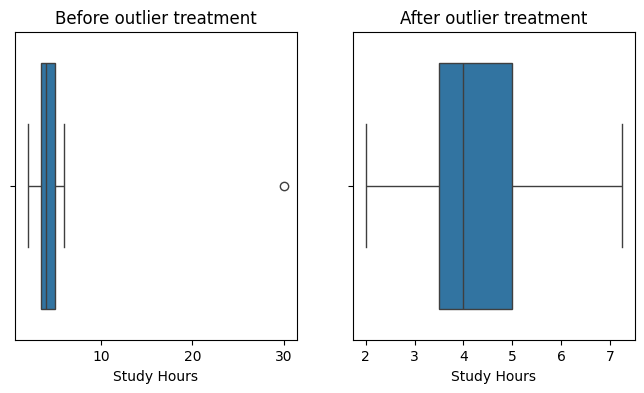

In [ ]:
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
sns.boxplot(x=df["Study_Hours"])
plt.title("Before outlier treatment")
plt.xlabel("Study Hours")

plt.subplot(1,2,2)
sns.boxplot(x=df_capped["Study_Hours"])
plt.title("After outlier treatment")
plt.xlabel("Study Hours")
plt.show()